In [1]:
import os, re, json, random, copy, time, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Carpeta de trabajo que replica la estructura del repositorio
BASE = Path.cwd() if Path.cwd().name == 'Dinosaurio' else Path.cwd() / 'Dinosaurio'
for sub in ['name_generator/data', 'name_generator/artifacts', 'docs/evidencias']:
    (BASE / sub).mkdir(parents=True, exist_ok=True)
os.chdir(BASE)  # desde aqui todas las rutas son relativas a la raiz del repo
print('Dispositivo:', DEVICE, '| directorio de trabajo:', Path.cwd())

Dispositivo: cuda | directorio de trabajo: /content/Dinosaurio


## 1. Datos



In [2]:
DATA_PATH = Path('name_generator/data/dinos.csv')
URLS = [
    'https://raw.githubusercontent.com/ALMA3112/Dinosaurio/main/name_generator/data/dinos.csv',
    'https://raw.githubusercontent.com/ArkaSarkar19/Character-level-language-model-Dinosaurus-Island/master/dinos.txt',
]

if not DATA_PATH.exists():
    import urllib.request
    for url in URLS:
        try:
            urllib.request.urlretrieve(url, DATA_PATH)
            print('Descargado de', url)
            break
        except Exception as e:
            print('No se pudo descargar', url, '->', e)
    else:
        from google.colab import files
        print('Suba el archivo dinos.csv:')
        up = files.upload()
        shutil.move(next(iter(up)), DATA_PATH)

def read_names(path):
    lines = [l.strip() for l in Path(path).read_text(encoding='utf-8-sig').splitlines() if l.strip()]
    if lines and lines[0].lower() == 'name':   # cabecera del CSV
        lines = lines[1:]
    return lines

raw_names = read_names(DATA_PATH)
print(len(raw_names), 'filas. Ejemplos:', raw_names[:5])

Descargado de https://raw.githubusercontent.com/ALMA3112/Dinosaurio/main/name_generator/data/dinos.csv
1536 filas. Ejemplos: ['Aachenosaurus', 'Aardonyx', 'Abdallahsaurus', 'Abelisaurus', 'Abrictosaurus']


## 2. Preprocesamiento

Orden de la guía: **normalizar → vocabulario → tokens especiales → longitud máxima T → padding → X/Y desplazados**.

### 2.1 Normalización y limpieza
El archivo crudo tiene ruido: nombres pegados sin separador (`AetonyxAfromimus`), la palabra `Skeleton` repetida y duplicados. Se separan los nombres pegados usando las mayúsculas internas, se pasa todo a minúsculas, se dejan solo letras a-z, y se eliminan duplicados.

In [3]:
STOPWORDS = {'skeleton'}

partes = []
for r in raw_names:
    # separa nombres pegados por mayuscula interna; descarta cualquier caracter que no sea letra a-z
    partes.extend(re.findall(r'[A-Z][a-z]*|[a-z]+', r))
n_extra = len(partes) - len(raw_names)

norm = [p.lower() for p in partes]                                  # mismo criterio de escritura
norm = [p for p in norm if p not in STOPWORDS and len(p) >= 3]      # fuera palabras que no son nombres
names = list(dict.fromkeys(norm))                                    # sin duplicados, conserva el orden

print(f'Filas crudas:                     {len(raw_names)}')
print(f'Nombres extra por separar pegados: {n_extra}')
print(f'Tras quitar stopwords/cortos:      {len(norm)}')
print(f'Nombres unicos finales:            {len(names)} (duplicados eliminados: {len(norm) - len(names)})')
print('Ejemplos:', names[:8])

Filas crudas:                     1536
Nombres extra por separar pegados: 10
Tras quitar stopwords/cortos:      1543
Nombres unicos finales:            1532 (duplicados eliminados: 11)
Ejemplos: ['aachenosaurus', 'aardonyx', 'abdallahsaurus', 'abelisaurus', 'abrictosaurus', 'abrosaurus', 'abydosaurus', 'acanthopholis']


### 2.2 Vocabulario, tokens especiales, T, padding y secuencias X/Y

Cada nombre se convierte en `[<SOS>, c1, ..., cn, <EOS>]`. Una secuencia `[x0, ..., xT]` tiene `T+1` elementos, así que `T = (longitud máxima de las secuencias) - 1`. Con `<PAD>` a la derecha se igualan las longitudes, y:

- `X = [x0, x1, ..., x(T-1)]`
- `Y = [x1, x2, ..., xT]`

In [4]:
SPECIALS = ['<PAD>', '<SOS>', '<EOS>']
chars = sorted(set(''.join(names)))
itos = SPECIALS + chars                       # id -> caracter
stoi = {c: i for i, c in enumerate(itos)}     # caracter -> id
PAD, SOS, EOS = stoi['<PAD>'], stoi['<SOS>'], stoi['<EOS>']
VOCAB_SIZE = len(itos)

seqs = [[SOS] + [stoi[c] for c in n] + [EOS] for n in names]
T = max(len(s) for s in seqs) - 1             # secuencia [x0..xT] tiene T+1 elementos
padded = np.array([s + [PAD] * (T + 1 - len(s)) for s in seqs], dtype=np.int64)

X = padded[:, :-1]    # [x0 .. x(T-1)]
Y = padded[:, 1:]     # [x1 .. xT]

# Division entrenamiento / validacion (90 / 10) por nombre
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(names))
n_val = int(0.1 * len(names))
val_idx, train_idx = perm[:n_val], perm[n_val:]
X_train, Y_train = X[train_idx], Y[train_idx]
X_val,   Y_val   = X[val_idx],   Y[val_idx]
train_names = [names[i] for i in train_idx]
val_names   = [names[i] for i in val_idx]

print('Vocabulario:', itos)
print(f'VOCAB_SIZE={VOCAB_SIZE}  T={T}  X: {X.shape}  Y: {Y.shape}')
print(f'Entrenamiento: {len(train_names)} nombres | Validacion: {len(val_names)} nombres')
dec = lambda row: ' '.join(itos[i] for i in row)
print('\nEjemplo:', names[0])
print('X =', dec(X[0][:12]), '...')
print('Y =', dec(Y[0][:12]), '...')

Vocabulario: ['<PAD>', '<SOS>', '<EOS>', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
VOCAB_SIZE=29  T=24  X: (1532, 24)  Y: (1532, 24)
Entrenamiento: 1379 nombres | Validacion: 153 nombres

Ejemplo: aachenosaurus
X = <SOS> a a c h e n o s a u r ...
Y = a a c h e n o s a u r u ...


## 3. Modelo y entrenamiento

El modelo es `Embedding → RNN/LSTM/GRU → Linear` sobre el vocabulario. Se escribe en un módulo propio (`name_generator/name_model.py`) que también reutilizará la aplicación web en la Fase 5, para cargar el modelo ya entrenado sin reentrenar.

El módulo incluye el muestreo: **temperatura**, **top-k** y **top-p** (nunca se muestrean `<PAD>` ni `<SOS>`).

In [5]:
%%writefile name_generator/name_model.py
"""Modelo de caracteres (RNN/LSTM/GRU) para generar nombres de dinosaurios.

Se usa tanto en el notebook de entrenamiento como en la aplicacion web (Fase 5).
"""
import json
from pathlib import Path

import torch
import torch.nn as nn


class CharRNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=32, hidden_size=128, num_layers=1,
                 rnn_type="GRU", dropout=0.0, pad_id=0):
        super().__init__()
        self.rnn_type = rnn_type.upper()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[self.rnn_type]
        self.rnn = rnn_cls(emb_dim, hidden_size, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, h=None):
        out, h = self.rnn(self.embedding(x), h)
        return self.fc(self.drop(out)), h


def _filter_logits(logits, top_k=None, top_p=None):
    """Aplica top-k y/o top-p a un vector de logits (1D)."""
    logits = logits.clone()
    if top_k is not None and top_k > 0:
        k = min(int(top_k), logits.size(-1))
        kth = torch.topk(logits, k).values[-1]
        logits[logits < kth] = float("-inf")
    if top_p is not None and top_p < 1.0:
        sorted_logits, sorted_idx = torch.sort(logits, descending=True)
        probs = torch.softmax(sorted_logits, dim=-1)
        cum = torch.cumsum(probs, dim=-1)
        remove = (cum - probs) >= top_p      # conserva el conjunto minimo cuya prob. acumulada alcanza p
        sorted_logits[remove] = float("-inf")
        logits = torch.full_like(logits, float("-inf")).scatter(0, sorted_idx, sorted_logits)
    return logits


@torch.no_grad()
def sample_name(model, vocab, temperature=1.0, top_k=None, top_p=None, min_len=3, max_len=None):
    """Genera un nombre de forma autoregresiva: cada caracter producido alimenta el siguiente paso."""
    model.eval()
    device = next(model.parameters()).device
    itos = vocab["itos"]
    pad, sos, eos = vocab["pad_id"], vocab["sos_id"], vocab["eos_id"]
    max_len = max_len or vocab["max_len"]

    x = torch.tensor([[sos]], device=device)
    h, out = None, []
    for step in range(max_len):
        logits, h = model(x, h)
        logits = logits[0, -1].float().clone()
        logits[pad] = float("-inf")
        logits[sos] = float("-inf")
        if step < min_len:
            logits[eos] = float("-inf")       # evita nombres demasiado cortos
        logits = logits / max(float(temperature), 1e-6)
        logits = _filter_logits(logits, top_k, top_p)
        probs = torch.softmax(logits, dim=-1)
        idx = torch.multinomial(probs, 1).item()
        if idx == eos:
            break
        out.append(itos[idx])
        x = torch.tensor([[idx]], device=device)
    return "".join(out)


def generate_novel(model, vocab, known, n=1, min_len=5, max_tries=1000, **sampling):
    """Devuelve hasta n nombres unicos que NO estan en `known` (conjunto de entrenamiento)."""
    found, seen = [], set()
    for _ in range(max_tries):
        name = sample_name(model, vocab, **sampling)
        if len(name) >= min_len and name not in known and name not in seen:
            found.append(name)
            seen.add(name)
            if len(found) == n:
                break
    return found


def load_model(artifacts_dir="name_generator/artifacts", device="cpu"):
    """Carga el modelo ya entrenado (sin reentrenar). Devuelve (model, vocab, known_names)."""
    d = Path(artifacts_dir)
    vocab = json.loads((d / "vocab.json").read_text(encoding="utf-8"))
    ckpt = torch.load(d / "char_model.pt", map_location=device, weights_only=True)
    model = CharRNN(**ckpt["model_kwargs"]).to(device)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    known = set(json.loads((d / "training_names.json").read_text(encoding="utf-8")))
    return model, vocab, known

Writing name_generator/name_model.py


In [6]:
import sys
sys.path.insert(0, str(Path.cwd() / 'name_generator'))
from name_model import CharRNN, sample_name, generate_novel

# Pagina de configuraciones a comparar (se registran todos los hiperparametros)
CONFIGS = [
    dict(name='A_GRU_1x128',  arch='GRU',  num_layers=1, hidden_size=128, emb_dim=32,
         dropout=0.0, epochs=60, batch_size=64, lr=3e-3, loss='CrossEntropy (ignore_index=<PAD>)', optimizer='Adam'),
    dict(name='B_LSTM_2x256', arch='LSTM', num_layers=2, hidden_size=256, emb_dim=64,
         dropout=0.3, epochs=60, batch_size=64, lr=2e-3, loss='CrossEntropy (ignore_index=<PAD>)', optimizer='Adam'),
]

criterion = nn.CrossEntropyLoss(ignore_index=PAD)   # <PAD> excluido del calculo de la perdida

def make_loader(Xa, Ya, batch_size, shuffle):
    ds = TensorDataset(torch.tensor(Xa), torch.tensor(Ya))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

def run_epoch(model, loader, optimizer=None, clip=1.0):
    training = optimizer is not None
    model.train(training)
    total, n_tok = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        with torch.set_grad_enabled(training):
            logits, _ = model(xb)
            loss = criterion(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))
        if training:
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
        k = (yb != PAD).sum().item()          # promedio ponderado por tokens reales (sin PAD)
        total += loss.item() * k
        n_tok += k
    return total / n_tok

def train_config(cfg):
    torch.manual_seed(SEED)
    model_kwargs = dict(vocab_size=VOCAB_SIZE, emb_dim=cfg['emb_dim'], hidden_size=cfg['hidden_size'],
                        num_layers=cfg['num_layers'], rnn_type=cfg['arch'], dropout=cfg['dropout'], pad_id=PAD)
    model = CharRNN(**model_kwargs).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    tr = make_loader(X_train, Y_train, cfg['batch_size'], True)
    va = make_loader(X_val, Y_val, cfg['batch_size'], False)
    hist = {'train': [], 'val': []}
    best = {'val': float('inf'), 'epoch': 0, 'state': None}
    t0 = time.time()
    for ep in range(1, cfg['epochs'] + 1):
        tl = run_epoch(model, tr, opt)
        vl = run_epoch(model, va)
        hist['train'].append(tl); hist['val'].append(vl)
        if vl < best['val']:
            best = {'val': vl, 'epoch': ep, 'state': copy.deepcopy(model.state_dict())}
        if ep % 10 == 0 or ep == 1:
            print(f"  [{cfg['name']}] epoca {ep:3d}  train={tl:.4f}  val={vl:.4f}")
    n_params = sum(p.numel() for p in model.parameters())
    print(f"  -> mejor val={best['val']:.4f} en la epoca {best['epoch']} | {n_params:,} parametros | {time.time()-t0:.0f}s")
    return dict(cfg=cfg, model_kwargs=model_kwargs, hist=hist, best=best, n_params=n_params)

In [7]:
results = []
for cfg in CONFIGS:
    print('Entrenando', cfg['name'], '...')
    results.append(train_config(cfg))

Entrenando A_GRU_1x128 ...
  [A_GRU_1x128] epoca   1  train=2.6144  val=2.1800
  [A_GRU_1x128] epoca  10  train=1.4944  val=1.6061
  [A_GRU_1x128] epoca  20  train=1.1682  val=1.6320
  [A_GRU_1x128] epoca  30  train=0.9064  val=1.7818
  [A_GRU_1x128] epoca  40  train=0.7624  val=1.9334
  [A_GRU_1x128] epoca  50  train=0.6938  val=2.0884
  [A_GRU_1x128] epoca  60  train=0.6603  val=2.2001
  -> mejor val=1.5793 en la epoca 13 | 66,877 parametros | 6s
Entrenando B_LSTM_2x256 ...
  [B_LSTM_2x256] epoca   1  train=2.7212  val=2.2847
  [B_LSTM_2x256] epoca  10  train=1.5039  val=1.5915
  [B_LSTM_2x256] epoca  20  train=1.0964  val=1.6313
  [B_LSTM_2x256] epoca  30  train=0.8419  val=1.8083
  [B_LSTM_2x256] epoca  40  train=0.7403  val=2.0039
  [B_LSTM_2x256] epoca  50  train=0.6987  val=2.0976
  [B_LSTM_2x256] epoca  60  train=0.6825  val=2.1506
  -> mejor val=1.5713 en la epoca 13 | 865,373 parametros | 8s


### 3.1 Registro de configuraciones y curvas de pérdida

,0,1
configuracion,A_GRU_1x128,B_LSTM_2x256
arquitectura,GRU,LSTM
capas,1,2
estado_oculto,128,256
emb_dim,32,64
dropout,0.0,0.3
epocas,60,60
batch,64,64
lr,0.003,0.002
funcion_perdida,CrossEntropy (ignore_index=<PAD>),CrossEntropy (ignore_index=<PAD>)


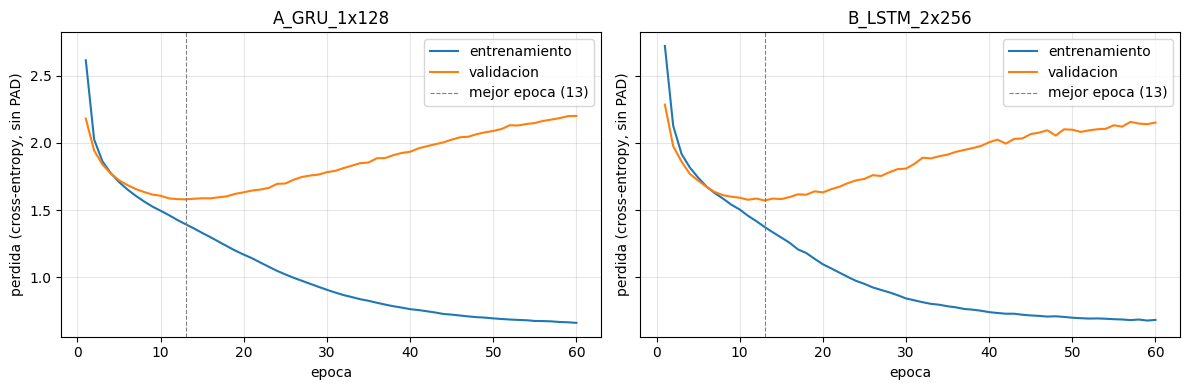

In [8]:
rows = []
for r in results:
    c, b = r['cfg'], r['best']
    rows.append({
        'configuracion': c['name'], 'arquitectura': c['arch'], 'capas': c['num_layers'],
        'estado_oculto': c['hidden_size'], 'emb_dim': c['emb_dim'], 'dropout': c['dropout'],
        'epocas': c['epochs'], 'batch': c['batch_size'], 'lr': c['lr'],
        'funcion_perdida': c['loss'], 'optimizador': c['optimizer'], 'parametros': r['n_params'],
        'train_final': round(r['hist']['train'][-1], 4), 'val_final': round(r['hist']['val'][-1], 4),
        'mejor_val': round(b['val'], 4), 'mejor_epoca': b['epoch'],
    })
summary = pd.DataFrame(rows)
summary.to_csv('docs/configuraciones_entrenamiento.csv', index=False)
display(summary.T)

fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 4), sharey=True)
for ax, r in zip(np.atleast_1d(axes), results):
    ep = range(1, len(r['hist']['train']) + 1)
    ax.plot(ep, r['hist']['train'], label='entrenamiento')
    ax.plot(ep, r['hist']['val'], label='validacion')
    ax.axvline(r['best']['epoch'], ls='--', c='gray', lw=0.8, label=f"mejor epoca ({r['best']['epoch']})")
    ax.set_title(r['cfg']['name']); ax.set_xlabel('epoca'); ax.set_ylabel('perdida (cross-entropy, sin PAD)')
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig('docs/evidencias/curvas_perdida.png', dpi=150)
plt.show()

In [9]:
# Seleccion del mejor modelo por perdida de validacion y guardado de artefactos
best_r = min(results, key=lambda r: r['best']['val'])
print('Modelo seleccionado:', best_r['cfg']['name'], '| val =', round(best_r['best']['val'], 4))

model = CharRNN(**best_r['model_kwargs']).to(DEVICE)
model.load_state_dict(best_r['best']['state'])
model.eval()

torch.save({'model_kwargs': best_r['model_kwargs'],
            'state_dict': {k: v.cpu() for k, v in model.state_dict().items()},
            'config': best_r['cfg']}, 'name_generator/artifacts/char_model.pt')

vocab = {'itos': itos, 'pad_id': PAD, 'sos_id': SOS, 'eos_id': EOS, 'max_len': T}
Path('name_generator/artifacts/vocab.json').write_text(json.dumps(vocab, indent=2), encoding='utf-8')
Path('name_generator/artifacts/training_names.json').write_text(json.dumps(names), encoding='utf-8')
Path('docs/modelo_seleccionado.json').write_text(json.dumps(
    {'config': best_r['cfg'], 'parametros': best_r['n_params'], 'mejor_epoca': best_r['best']['epoch'],
     'mejor_val': best_r['best']['val'], 'T': T, 'vocab_size': VOCAB_SIZE}, indent=2), encoding='utf-8')
print(model)

Modelo seleccionado: B_LSTM_2x256 | val = 1.5713
CharRNN(
  (embedding): Embedding(29, 64, padding_idx=0)
  (rnn): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.3)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=29, bias=True)
)


## 4. Generación y muestreo

En cada paso el modelo produce una distribución sobre el vocabulario y se elige el siguiente carácter con estas estrategias:

- **Temperatura:** divide los logits; valores bajos favorecen lo previsible, valores altos aumentan la diversidad.
- **Top-k:** solo compite el grupo de los *k* caracteres más probables.
- **Top-p:** solo compite el conjunto más pequeño cuya probabilidad acumulada alcanza *p*.

Se evalúan 6 configuraciones (tres temperaturas, una de ellas 1.0, más top-k y top-p). No se prueban todas las combinaciones. Para cada una se generan 300 nombres y se mide qué porcentaje es nuevo (no está en el conjunto de entrenamiento), qué porcentaje es único, la longitud media y cuántos terminan en sufijos típicos.

In [10]:
known = set(names)
SUFFIXES = ('saurus', 'raptor', 'odon', 'venator', 'mimus', 'titan', 'ceratops', 'nykus', 'pelta')

SAMPLING_CONFIGS = [
    dict(name='T=0.5',          temperature=0.5, top_k=None, top_p=None),
    dict(name='T=1.0',          temperature=1.0, top_k=None, top_p=None),
    dict(name='T=1.3',          temperature=1.3, top_k=None, top_p=None),
    dict(name='T=1.0 + top-k=5',   temperature=1.0, top_k=5,    top_p=None),
    dict(name='T=1.0 + top-p=0.9', temperature=1.0, top_k=None, top_p=0.9),
    dict(name='T=1.3 + top-p=0.9', temperature=1.3, top_k=None, top_p=0.9),
]

def evaluate_sampling(cfg, n=300, seed=0):
    torch.manual_seed(seed)
    gen = [sample_name(model, vocab, temperature=cfg['temperature'], top_k=cfg['top_k'], top_p=cfg['top_p'])
           for _ in range(n)]
    novel = [g for g in gen if g not in known]
    return {
        'muestreo': cfg['name'], 'temperatura': cfg['temperature'], 'top_k': cfg['top_k'], 'top_p': cfg['top_p'],
        '%_nuevos': round(100 * len(novel) / n, 1),
        '%_unicos': round(100 * len(set(gen)) / n, 1),
        'long_media': round(float(np.mean([len(g) for g in gen])), 1),
        '%_sufijo_tipico': round(100 * np.mean([g.endswith(SUFFIXES) for g in gen]), 1),
        'ejemplos_nuevos': ', '.join(list(dict.fromkeys(novel))[:5]),
    }

sampling_df = pd.DataFrame([evaluate_sampling(c) for c in SAMPLING_CONFIGS])
sampling_df.to_csv('docs/comparacion_muestreo.csv', index=False)
pd.set_option('display.max_colwidth', 80)
display(sampling_df)

,muestreo,temperatura,top_k,top_p,%_nuevos,%_unicos,long_media,%_sufijo_tipico,ejemplos_nuevos
0,T=0.5,0.5,NaN,NaN,85.7,92.3,11.6,87.3,"angungsaurus, placroceratops, boryphosaurus, sphiselosaurus, alacanthosaurus"
1,T=1.0,1.0,NaN,NaN,98.3,100.0,12.0,65.0,"zunandssaurus, nanotolosaurus, ornathorlentosaurus, faninshousaurus, micropa..."
2,T=1.3,1.3,NaN,NaN,100.0,100.0,12.3,47.3,"zunandssaurus, nmerhonosaurus, ornathkilengx, phipelosuchus, coacstenyx"
3,T=1.0 + top-k=5,1.0,5.0,NaN,96.7,95.3,11.7,73.7,"angunsaurus, anganosaurus, parosaurus, tarchysphus, argosauros"
4,T=1.0 + top-p=0.9,1.0,NaN,0.9,97.0,99.3,12.0,81.0,"zunandrosaurus, marhenosaurus, ornathoraptor, phiaelosaurus, aoacanthus"
5,T=1.3 + top-p=0.9,1.3,NaN,0.9,99.0,100.0,12.0,62.3,"zunandssaurus, nanotolosaurus, ornathoraptor, phipelosuchus, coacstenyx"


### 4.1 Diez nombres nuevos y selección

Se toman nombres **que no coinciden con ninguno del conjunto de entrenamiento**, repartidos entre las configuraciones de muestreo (turnos rotativos), y se selecciona uno. Por defecto se propone el primero con longitud 8-16 y un sufijo típico (`-saurus`, `-raptor`, ...); se puede forzar otro escribiendo `SELECTED_NAME`.

In [11]:
pool = {}
for cfg in SAMPLING_CONFIGS:
    torch.manual_seed(100)
    pool[cfg['name']] = generate_novel(model, vocab, known, n=8,
                                       temperature=cfg['temperature'], top_k=cfg['top_k'], top_p=cfg['top_p'])

ten, seen = [], set()
for i in range(8):
    for cfg in SAMPLING_CONFIGS:
        lst = pool[cfg['name']]
        if i < len(lst) and lst[i] not in seen and len(ten) < 10:
            ten.append({'nombre': lst[i], 'muestreo': cfg['name']})
            seen.add(lst[i])

ten_df = pd.DataFrame(ten)
ten_df.insert(0, '#', range(1, len(ten_df) + 1))
ten_df['en_entrenamiento'] = ten_df['nombre'].isin(known)
assert len(ten_df) == 10 and not ten_df['en_entrenamiento'].any(), 'Deben ser 10 nombres nuevos'
display(ten_df)
ten_df.to_csv('docs/nombres_generados.csv', index=False)

SELECTED_NAME = None   # opcional: escriba aqui uno de la tabla, por ejemplo 'xxxxsaurus'
cands = [r for r in ten if r['nombre'].endswith(SUFFIXES) and 8 <= len(r['nombre']) <= 16]
chosen = next((r for r in ten if r['nombre'] == SELECTED_NAME), None) if SELECTED_NAME else None
chosen = chosen or (cands[0] if cands else ten[0])

selected = {'name': chosen['nombre'].capitalize(), 'name_raw': chosen['nombre'],
            'sampling': chosen['muestreo'], 'model': best_r['cfg']['name']}
Path('name_generator/artifacts/nombre_seleccionado.json').write_text(json.dumps(selected, indent=2), encoding='utf-8')
print('Nombre seleccionado:', selected['name'], '| muestreo:', selected['sampling'], '| modelo:', selected['model'])

,#,nombre,muestreo,en_entrenamiento
0,1,calalosaurus,T=0.5,False
1,2,calhadopis,T=1.3,False
2,3,calastomis,T=1.0 + top-k=5,False
3,4,calalobans,T=1.3 + top-p=0.9,False
4,5,junangosaurus,T=0.5,False
5,6,junansianophelion,T=1.0,False
6,7,dracramosaurus,T=1.3,False
7,8,stetramosaurus,T=1.0 + top-k=5,False
8,9,junansianophelia,T=1.0 + top-p=0.9,False
9,10,chuanghengosaurus,T=0.5,False


Nombre seleccionado: Calalosaurus | muestreo: T=0.5 | modelo: B_LSTM_2x256


## 5. Evidencias y paquete para el repositorio

Se genera `docs/analisis_nombres.md` con los resultados y se empaqueta todo en `fase1_resultados.zip`. Después de ejecutar, **lea los números y complete la interpretación** en ese archivo (o en la celda de abajo).

In [12]:
def df_to_md(df):
    cols = list(df.columns)
    lines = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '---|' * len(cols)]
    for _, row in df.iterrows():
        lines.append('| ' + ' | '.join(str(row[c]) for c in cols) + ' |')
    return '\n'.join(lines)

s = sampling_df
hi, lo = s.loc[s['%_nuevos'].idxmax()], s.loc[s['%_nuevos'].idxmin()]
divr = s.loc[s['%_unicos'].idxmax()]
cfg_cols = ['configuracion', 'arquitectura', 'capas', 'estado_oculto', 'epocas', 'funcion_perdida',
            'optimizador', 'parametros', 'mejor_val', 'mejor_epoca']

analysis = f"""# Evidencias: generador de nombres

## Arquitectura y configuraciones evaluadas
{df_to_md(summary[cfg_cols])}

Modelo seleccionado: **{best_r['cfg']['name']}** (menor perdida de validacion: {best_r['best']['val']:.4f}).
Vocabulario: {VOCAB_SIZE} tokens (a-z + <PAD>, <SOS>, <EOS>). T = {T}. Nombres unicos tras la limpieza: {len(names)}
({len(train_names)} entrenamiento / {len(val_names)} validacion). <PAD> excluido de la perdida con `ignore_index`.

Curvas de perdida: `docs/evidencias/curvas_perdida.png`.

## Configuraciones de muestreo
{df_to_md(sampling_df)}

## Diez nombres generados (ninguno esta en el conjunto de entrenamiento)
{df_to_md(ten_df[['#', 'nombre', 'muestreo']])}

**Nombre seleccionado:** {selected['name']} (muestreo {selected['sampling']}).

## Analisis (valores medidos sobre 300 nombres por configuracion)
- Mayor porcentaje de nombres nuevos: **{hi['muestreo']}** ({hi['%_nuevos']} %). Menor: **{lo['muestreo']}** ({lo['%_nuevos']} %).
- Mayor diversidad (porcentaje de nombres unicos): **{divr['muestreo']}** ({divr['%_unicos']} %).
- Con temperatura baja el modelo tiende a repetir patrones frecuentes y a reproducir nombres del conjunto de entrenamiento;
  con temperatura alta aumenta la novedad, pero pueden aparecer secuencias menos pronunciables.
- Top-k y top-p recortan la cola de caracteres improbables y permiten usar temperaturas altas manteniendo nombres mas plausibles.

## Interpretacion propia (completar)
- Que configuracion de entrenamiento rindio mejor y por que (compare curvas, sobreajuste, tamanos).
- Que muestreo da el mejor equilibrio entre novedad y verosimilitud segun los nombres obtenidos.
"""
Path('docs/analisis_nombres.md').write_text(analysis, encoding='utf-8')
print(analysis[:1500], '...')

shutil.make_archive('/tmp/fase1_resultados', 'zip', root_dir=Path.cwd())
shutil.copy('/tmp/fase1_resultados.zip', 'fase1_resultados.zip')
try:
    from google.colab import files
    files.download('fase1_resultados.zip')
except ImportError:
    print('Archivo creado:', Path('fase1_resultados.zip').resolve())

# Evidencias: generador de nombres

## Arquitectura y configuraciones evaluadas
| configuracion | arquitectura | capas | estado_oculto | epocas | funcion_perdida | optimizador | parametros | mejor_val | mejor_epoca |
|---|---|---|---|---|---|---|---|---|---|
| A_GRU_1x128 | GRU | 1 | 128 | 60 | CrossEntropy (ignore_index=<PAD>) | Adam | 66877 | 1.5793 | 13 |
| B_LSTM_2x256 | LSTM | 2 | 256 | 60 | CrossEntropy (ignore_index=<PAD>) | Adam | 865373 | 1.5713 | 13 |

Modelo seleccionado: **B_LSTM_2x256** (menor perdida de validacion: 1.5713).
Vocabulario: 29 tokens (a-z + <PAD>, <SOS>, <EOS>). T = 24. Nombres unicos tras la limpieza: 1532
(1379 entrenamiento / 153 validacion). <PAD> excluido de la perdida con `ignore_index`.

Curvas de perdida: `docs/evidencias/curvas_perdida.png`.

## Configuraciones de muestreo
| muestreo | temperatura | top_k | top_p | %_nuevos | %_unicos | long_media | %_sufijo_tipico | ejemplos_nuevos |
|---|---|---|---|---|---|---|---|---|
| T=0.5 | 0.5 | nan | nan | 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Después de descargar `fase1_resultados.zip`
1. Descomprímalo **dentro de la raíz del repositorio** (`PLN/Dinosaurio`) para que queden `name_generator/artifacts/`, `docs/...`, etc.
2. Guarde este notebook como `name_generator/01_generador_nombres.ipynb` (en Colab: *Archivo → Descargar → .ipynb*).
3. Complete la interpretación en `docs/analisis_nombres.md`.
4. `git add -A && git commit -m "fase-1: generador de nombres + evidencias" && git push`